# Login, GPU check

In [1]:
# Cell 1
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

# Cell 2
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()
print(torch.cuda.device_count())

# Cell 3
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF2")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
print("Hugging Face login successful.")

# Cell 4
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

1


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.
CUDA available: True
GPU count: 1
GPU 0: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [2]:
import os, random, json, time, math, zipfile, shutil
import numpy as np
import torch

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_TEXT_FILES = ["Phase_2_LNER/Train/fold1-text.json", "Phase_2_LNER/Train/fold2-text.json"]
TRAIN_GOLD_FILES = ["Phase_2_LNER/Train/fold1-gold.json", "Phase_2_LNER/Train/fold2-gold.json"]
LABELS_FILE = "Phase_2_LNER/Train/labels.txt"
TEST_TEXT_FILE = "Phase_2_LNER/Test/fold3-text.json"

# ---------------- Phase 1 backbone: Model 1 (GPT-2 scratch) ----------------
PHASE1_CKPT_DIR = "/kaggle/input/datasets/himangshumahato/gpt2-decoder-model"
MODEL_CONTEXT_LENGTH = 1024
N_EMBD = 768
N_LAYER = 12
N_HEAD = 12

# ---------------- NER data / windowing ----------------
WINDOW_SIZE = 1024
WINDOW_STRIDE = 512
HEADER_TOKENS = 64

# ---------------- LoRMA ----------------
LORMA_R = 8
LORMA_ALPHA = 16
LORMA_TARGETS = ["c_attn", "c_proj", "c_fc"]   # substring match against module names

# ---------------- Training ----------------
EPOCHS = 15
BATCH_SIZE = 8
GRAD_ACCUM = 2
LR_LORMA = 1e-3
LR_HEAD = 1e-3
WEIGHT_DECAY = 0.05
WARMUP_RATIO = 0.10
SEED = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

EXPERIMENT_NAME = "gpt2_lorma"
OUTPUT_DIR = f"/kaggle/working/cs781_phase2/{EXPERIMENT_NAME}"
MODEL_PATH = os.path.join(OUTPUT_DIR, "best_model.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Configuration loaded:", EXPERIMENT_NAME)

Configuration loaded: gpt2_lorma


In [3]:
!pip -q install regex
from huggingface_hub import hf_hub_download, HfApi

info = HfApi().dataset_info(HF_DATASET_REPO, files_metadata=True, token=HF_TOKEN)
for s in info.siblings:
    if "Phase_2" in s.rfilename:
        print(f"{s.rfilename:70s} {s.size/1e6:.2f} MB")

Phase_2_LNER/Test/fold3-text.json                                      1.19 MB
Phase_2_LNER/Train/fold1-gold.json                                     0.46 MB
Phase_2_LNER/Train/fold1-text.json                                     1.11 MB
Phase_2_LNER/Train/fold2-gold.json                                     0.48 MB
Phase_2_LNER/Train/fold2-text.json                                     1.12 MB
Phase_2_LNER/Train/labels.txt                                          0.00 MB


## 4. Load Tokenizer

In [4]:
%%writefile a1_tokenizer.py
"""From-scratch byte-level BPE tokenizer (GPT-2 style)."""
from __future__ import annotations
import heapq, json, time
from collections import Counter, defaultdict
import regex as re

_PAT = re.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")
EOS_TOKEN = "<|endoftext|>"

class ByteLevelBPE:
    def __init__(self):
        self.merges: dict[tuple[int, int], int] = {}
        self.itos: dict[int, bytes] = {i: bytes([i]) for i in range(256)}
        self.eos_token_id = 256
        self.vocab_size = 257
        self._cache: dict[str, tuple] = {}

    @property
    def pad_token_id(self): return self.eos_token_id
    @property
    def bos_token_id(self): return self.eos_token_id
    def __len__(self): return self.vocab_size
    def get_vocab_size(self): return self.vocab_size

    def _encode_word(self, word):
        if word in self._cache:
            return self._cache[word]
        ids = list(word.encode("utf-8"))
        while len(ids) > 1:
            pairs = {(ids[i], ids[i+1]) for i in range(len(ids)-1)}
            ranked = [(self.merges[p], p) for p in pairs if p in self.merges]
            if not ranked:
                break
            _, best = min(ranked)
            new_id = self.merges[best]
            out, i = [], 0
            while i < len(ids):
                if i < len(ids)-1 and (ids[i], ids[i+1]) == best:
                    out.append(new_id); i += 2
                else:
                    out.append(ids[i]); i += 1
            ids = out
        self._cache[word] = tuple(ids)
        return tuple(ids)

    def encode(self, text, add_eos=False):
        out = []
        for w in _PAT.findall(text):
            out.extend(self._encode_word(w))
        if add_eos:
            out.append(self.eos_token_id)
        return out

    def decode(self, ids, skip_special_tokens=True):
        parts = []
        for i in ids:
            if i == self.eos_token_id:
                if skip_special_tokens:
                    continue
                parts.append(EOS_TOKEN.encode())
            else:
                parts.append(self.itos[i])
        return b"".join(parts).decode("utf-8", errors="replace")

    def save(self, path):
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"merges": [[list(p), n] for p, n in self.merges.items()],
                       "vocab_size": self.vocab_size, "eos_token_id": self.eos_token_id}, f)

    @classmethod
    def load(cls, path):
        with open(path, encoding="utf-8") as f:
            d = json.load(f)
        t = cls()
        for a, b, n in d["merges"]:
            t.merges[(a, b)] = n
            t.itos[n] = t.itos[a] + t.itos[b]
        t.eos_token_id = d["eos_token_id"]
        t.vocab_size = d["vocab_size"]
        return t

Overwriting a1_tokenizer.py


In [5]:
from a1_tokenizer import ByteLevelBPE, _PAT
tokenizer = ByteLevelBPE.load(os.path.join(PHASE1_CKPT_DIR, "bpe_tokenizer.json"))
print("Vocabulary size:", len(tokenizer))

Vocabulary size: 32000


In [6]:
def encode_with_offsets(tok, text):
    ids, starts, ends, is_ws = [], [], [], []
    pos = 0
    for m in _PAT.finditer(text):
        assert m.start() == pos, "pre-tokenizer left a gap in the text"
        pos = m.end()
        word, c0 = m.group(), m.start()
        b2c = []
        for i, ch in enumerate(word):
            b2c.extend([c0 + i] * len(ch.encode("utf-8")))
        b = 0
        for tid in tok._encode_word(word):
            n = len(tok.itos[tid])
            s, e = b2c[b], b2c[b + n - 1] + 1
            b += n
            while s < e and text[s].isspace(): s += 1
            while e > s and text[e - 1].isspace(): e -= 1
            ids.append(tid); starts.append(s); ends.append(e); is_ws.append(s >= e)
    assert pos == len(text), "pre-tokenizer did not cover the whole text"
    return ids, starts, ends, is_ws

# Data loading

In [7]:
from huggingface_hub import hf_hub_download

def hf_json(path):
    p = hf_hub_download(repo_id=HF_DATASET_REPO, filename=path, repo_type="dataset", token=HF_TOKEN)
    with open(p, encoding="utf-8") as f:
        return json.load(f)

train_text, train_gold, doc_fold = {}, {}, {}
for fold_i, (tf, gf) in enumerate(zip(TRAIN_TEXT_FILES, TRAIN_GOLD_FILES), start=1):
    t, g = hf_json(tf), hf_json(gf)
    train_text.update(t); train_gold.update(g)
    for d in t: doc_fold[d] = fold_i

test_text = hf_json(TEST_TEXT_FILE)
p = hf_hub_download(repo_id=HF_DATASET_REPO, filename=LABELS_FILE, repo_type="dataset", token=HF_TOKEN)
LABELS = [l.strip() for l in open(p, encoding="utf-8") if l.strip()]

print("train docs:", len(train_text), "| gold docs:", len(train_gold), "| test docs:", len(test_text))
print({f: sum(1 for v in doc_fold.values() if v == f) for f in (1, 2)})

train docs: 70 | gold docs: 70 | test docs: 35
{1: 35, 2: 35}


In [8]:
for d in list(train_text)[:5]:
    ids, s, e, w = encode_with_offsets(tokenizer, train_text[d])
    assert ids == tokenizer.encode(train_text[d]), d
print("ids match encode()")

n_tok = [len(encode_with_offsets(tokenizer, t)[0]) for t in train_text.values()]
print("tokens/doc min/mean/max:", min(n_tok), sum(n_tok)//len(n_tok), max(n_tok))

ids match encode()
tokens/doc min/mean/max: 2139 6618 23839


In [9]:
TAGS = ["O"] + [f"{p}-{l}" for l in LABELS for p in ("B", "I")]
TAG2ID = {t: i for i, t in enumerate(TAGS)}
ID2TAG = {i: t for t, i in TAG2ID.items()}
IGNORE = -100
print(len(TAGS), "tags:", TAGS[:5], "...")

25 tags: ['O', 'B-APP', 'I-APP', 'B-RESP', 'I-RESP'] ...


In [10]:
def spans_to_bio(starts, ends, is_ws, gold_spans):
    ents = sorted(gold_spans, key=lambda x: (x[0], x[1]))
    tags, k, prev_ent = [], 0, -1
    for i in range(len(starts)):
        if is_ws[i]:
            tags.append(IGNORE); continue
        while k < len(ents) and ents[k][1] <= starts[i]:
            k += 1
        if k < len(ents) and ents[k][0] <= starts[i] < ents[k][1]:
            prefix = "I-" if prev_ent == k else "B-"
            tags.append(TAG2ID[prefix + ents[k][2]]); prev_ent = k
        else:
            tags.append(TAG2ID["O"]); prev_ent = -1
    return tags

def bio_to_spans(starts, ends, is_ws, tag_ids):
    spans, cur = [], None
    for i, t in enumerate(tag_ids):
        if is_ws[i] or t == IGNORE: continue
        tag = ID2TAG[int(t)]
        if tag == "O":
            if cur: spans.append(cur); cur = None
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "I" and cur is not None and cur[2] == label:
            cur[1] = ends[i]
        else:
            if cur: spans.append(cur)
            cur = [starts[i], ends[i], label]
    if cur: spans.append(cur)
    return spans

In [11]:
def span_set(spans):
    return {tuple(x[:3]) for x in spans}

tp = ngold = 0
fails = []
for d, ents in train_gold.items():
    text = train_text[d]
    ids, s, e, w = encode_with_offsets(tokenizer, text)
    tags = spans_to_bio(s, e, w, ents)
    back = bio_to_spans(s, e, w, tags)
    g, b = span_set(ents), span_set(back)
    tp += len(g & b); ngold += len(g)
    for x in ents:
        if tuple(x[:3]) not in b:
            fails.append((d, x[0], x[1], x[2], text[max(0, x[0]-10):x[1]+10]))
print(f"round-trip recovery: {tp}/{ngold} = {tp/ngold:.4f}")
for f in fails[:15]: print(f)

round-trip recovery: 8242/8393 = 0.9820
('115651329', 10266, 10299, 'PREC', 'e case of State of M.P. vs. Kashiram & Ors.[1], the s')
('975074', 7995, 8085, 'PREC', '1565] and Gambangi Appalaswamy Naldu and Others v. Behara Venkataramanayya Patro [AIR 1984- SC 1728]. Even oth')
('736324', 1963, 1976, 'AUTH', ' down the Railway Boards instruct')
('736324', 11218, 11231, 'AUTH', 'tation of Railway Boards decision')
('736324', 12849, 12901, 'PREC', ' cases in Shankarsan Dash Vs. Union of India [1991 (3) SCC 47]. Para 7 o')
('736324', 14121, 14174, 'PREC', 'C 268] or Jatendra Kumar vs. State of Punjab [(1985) 1 SCC 122]. Hence th')
('1243363', 17853, 17865, 'STAT', 'After the Constitutional Amendme')
('1243363', 25083, 25099, 'AUTH', 'uding the State Governments and the ')
('1243363', 25450, 25466, 'AUTH', 'ws of the State Governments and the ')
('373587', 5927, 5979, 'PREC', 'son. (See Hukam Singh v. State of Rajasthan AIR (1977 SC 1063); Eradu an')
('373587', 5981, 6035, 'PREC', 'SC 1063)

## Encode every document once (train and test)

In [12]:
enc = {}
for d, t in {**train_text, **test_text}.items():
    enc[d] = encode_with_offsets(tokenizer, t)
tags_by_doc = {d: spans_to_bio(*enc[d][1:], train_gold[d]) for d in train_gold}
print("encoded docs:", len(enc), "| tagged docs:", len(tags_by_doc))

encoded docs: 105 | tagged docs: 70


## Windows

In [13]:
def window_starts(n_tokens, size, stride):
    if n_tokens <= size:
        return [0]
    starts = list(range(0, n_tokens - size + 1, stride))
    if starts[-1] + size < n_tokens:
        starts.append(n_tokens - size)
    return starts

def build_windows(doc_ids, size=WINDOW_SIZE, stride=WINDOW_STRIDE, with_labels=True, header_tokens=HEADER_TOKENS):
    items = []
    body_size = size - header_tokens
    for d in doc_ids:
        ids = enc[d][0]
        tags = tags_by_doc.get(d) if with_labels else None
        n = len(ids)
        header_ids = ids[:header_tokens]
        for ws in window_starts(n, body_size, stride):
            if ws == 0:
                input_ids = ids[0:size]; body_start = 0
            else:
                input_ids = header_ids + ids[ws:ws + body_size]; body_start = header_tokens
            body_len = len(input_ids) - body_start
            item = {"doc": d, "doc_start": ws, "body_start": body_start, "input_ids": input_ids}
            if with_labels:
                item["labels"] = [IGNORE] * body_start + tags[ws:ws + body_len]
            items.append(item)
    return items

fold1_docs = [d for d, f in doc_fold.items() if f == 1]
fold2_docs = [d for d, f in doc_fold.items() if f == 2]

all_docs = fold1_docs + fold2_docs
random.Random(SEED).shuffle(all_docs)
n_val = max(1, int(0.1 * len(all_docs)))
val_docs, train_docs = all_docs[:n_val], all_docs[n_val:]

train_items = build_windows(train_docs)
val_items   = build_windows(val_docs)
print(f"train docs: {len(train_docs)} | val docs: {len(val_docs)} | train windows: {len(train_items)} | val windows: {len(val_items)}")

for d in train_docs[:5]:
    covered = set()
    for it in train_items:
        if it["doc"] == d:
            body_len = len(it["input_ids"]) - it["body_start"]
            covered.update(range(it["doc_start"], it["doc_start"] + body_len))
    assert covered == set(range(len(enc[d][0]))), d
print("window coverage OK")

train docs: 63 | val docs: 7 | train windows: 807 | val windows: 73
window coverage OK


## Collator

In [14]:
PAD_ID = tokenizer.eos_token_id

def ner_collator(batch):
    L = WINDOW_SIZE
    ids = torch.full((len(batch), L), PAD_ID, dtype=torch.long)
    lab = torch.full((len(batch), L), IGNORE, dtype=torch.long)
    mask = torch.zeros((len(batch), L), dtype=torch.bool)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"])
        mask[i, :n] = True
        if "labels" in b:
            lab[i, :n] = torch.tensor(b["labels"])
    return {"input_ids": ids, "attention_mask": mask, "labels": lab}

b = ner_collator(train_items[:4])
print({k: v.shape for k, v in b.items()})

{'input_ids': torch.Size([4, 1024]), 'attention_mask': torch.Size([4, 1024]), 'labels': torch.Size([4, 1024])}


In [15]:
ent_frac = np.mean([any(l not in (0, IGNORE) for l in it["labels"]) for it in train_items])
print(f"windows containing at least one entity: {ent_frac:.2%}")

windows containing at least one entity: 99.38%


## 9. Define The Model

## GPT2-from scratch



In [16]:
import math
import torch.nn as nn
import torch.nn.functional as F

class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, n_positions, dropout=0.1):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.n_embd = n_embd
        self.head_dim = n_embd // n_head
        self.c_attn = nn.Linear(n_embd, 3 * n_embd)
        self.c_proj = nn.Linear(n_embd, n_embd)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer(
            "bias", torch.tril(torch.ones(n_positions, n_positions)).view(1, 1, n_positions, n_positions)
        )

    def forward(self, x, layer_past=None, attn_mask=None):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        if layer_past is not None:
            past_k, past_v = layer_past
            k = torch.cat([past_k, k], dim=-2)
            v = torch.cat([past_v, v], dim=-2)
        present = (k, v)
        past_length = layer_past[0].size(-2) if layer_past is not None else 0
        seq_len = T + past_length

        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(self.head_dim))

        if attn_mask is not None:
            # attn_mask: True = allowed, shape (B, 1, T, seq_len) — NER uses this for bidirectional + padding
            att = att.masked_fill(~attn_mask, float('-inf'))
        else:
            mask = self.bias[:, :, past_length:past_length + T, :seq_len] == 0
            att = att.masked_fill(mask, float('-inf'))

        att = F.softmax(att, dim=-1)
        att = self.attn_dropout(att)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.c_proj(y)), present


class MLP(nn.Module):
    def __init__(self, n_embd, dropout=0.1):
        super().__init__()
        self.c_fc = nn.Linear(n_embd, 4 * n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.c_proj(self.gelu(self.c_fc(x))))


class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, n_positions, dropout=0.1):
        super().__init__()
        self.ln_1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, n_positions, dropout)
        self.ln_2 = nn.LayerNorm(n_embd)
        self.mlp = MLP(n_embd, dropout)

    def forward(self, x, layer_past=None, attn_mask=None):
        a, present = self.attn(self.ln_1(x), layer_past=layer_past, attn_mask=attn_mask)
        x = x + a
        x = x + self.mlp(self.ln_2(x))
        return x, present


class GPT2ScratchLM(nn.Module):
    def __init__(self, vocab_size, n_positions, n_embd, n_layer, n_head, dropout=0.1):
        super().__init__()
        self.wte = nn.Embedding(vocab_size, n_embd)
        self.wpe = nn.Embedding(n_positions, n_embd)
        self.drop = nn.Dropout(dropout)
        self.h = nn.ModuleList([TransformerBlock(n_embd, n_head, n_positions, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)
        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("c_proj.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None: nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, labels=None, past_key_values=None, attn_mask=None, **kwargs):
        B, T = input_ids.size()
        past_length = past_key_values[0][0].size(-2) if past_key_values is not None else 0
        pos = torch.arange(past_length, past_length + T, dtype=torch.long, device=input_ids.device)
        x = self.wte(input_ids) + self.wpe(pos)
        x = self.drop(x)
        presents = []
        for i, block in enumerate(self.h):
            layer_past = past_key_values[i] if past_key_values is not None else None
            x, present = block(x, layer_past=layer_past, attn_mask=attn_mask)
            presents.append(present)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if labels is not None:
            shift_logits = logits[..., :-1, :].contiguous()
            shift_labels = labels[..., 1:].contiguous()
            loss = F.cross_entropy(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))
        return {"loss": loss, "logits": logits, "past_key_values": tuple(presents)}

## The LoRMA technique

In [17]:
class LoRMALinear(nn.Module):
    """Low-Rank Multiplicative Adaptation (LoRMA+), Jain & Modi et al., ACL Findings 2025.
    W' = (I_d + (alpha/r) * B @ A) @ W0   — a rank-inflated multiplicative update,
    contrasted with LoRA's additive  W' = W0 + (alpha/r) * B @ A.
    """
    def __init__(self, base_linear: nn.Linear, r=8, alpha=16):
        super().__init__()
        self.base = base_linear
        for p in self.base.parameters():
            p.requires_grad = False
        d_out = base_linear.out_features
        self.r = r
        self.alpha = alpha
        self.B = nn.Parameter(torch.zeros(d_out, r))
        self.A = nn.Parameter(torch.randn(r, d_out) * 0.01)
        self.register_buffer("eye", torch.eye(d_out))

    def forward(self, x):
        BA = self.B @ self.A                               # (d_out, d_out), rank <= r
        M = self.eye + (self.alpha / self.r) * BA           # rank-inflated multiplicative factor
        W_eff = M @ self.base.weight                        # (d_out, d_out) @ (d_out, d_in)
        return F.linear(x, W_eff, self.base.bias)


def apply_lorma(model, target_substrings, r=LORMA_R, alpha=LORMA_ALPHA):
    """Replace every nn.Linear whose name contains one of target_substrings with a LoRMALinear."""
    for parent_name, parent in model.named_modules():
        for child_name, child in list(parent.named_children()):
            if isinstance(child, nn.Linear) and any(t in child_name for t in target_substrings):
                setattr(parent, child_name, LoRMALinear(child, r=r, alpha=alpha))
    return model

# The NEW model

In [18]:
class LoRMANERModel(nn.Module):
    def __init__(self, lm, n_tags, dropout=0.1, bidirectional=True):
        super().__init__()
        self.lm = lm
        self.bidirectional = bidirectional
        if hasattr(self.lm, "lm_head"):
            del self.lm.lm_head

        self.dropout = nn.Dropout(dropout)
        self.head = nn.Sequential(
            nn.Linear(N_EMBD, N_EMBD),
            nn.GELU(approximate='tanh'),
            nn.Dropout(dropout),
            nn.Linear(N_EMBD, n_tags)
        )
        # head is always trainable; backbone trainability is controlled by apply_lorma
        for p in self.head.parameters():
            p.requires_grad = True

    def forward(self, input_ids, labels=None, attention_mask=None, class_weights=None):
        B, T = input_ids.shape
        positions = torch.arange(T, device=input_ids.device)
        x = self.lm.wte(input_ids) + self.lm.wpe(positions)
        x = self.lm.drop(x)

        if self.bidirectional:
            attn_mask = torch.ones(B, 1, T, T, dtype=torch.bool, device=input_ids.device)
        else:
            attn_mask = torch.tril(torch.ones(T, T, dtype=torch.bool, device=input_ids.device)).view(1, 1, T, T).expand(B, -1, -1, -1)

        if attention_mask is not None:
            key_visible = attention_mask[:, None, None, :].bool()
            attn_mask = attn_mask & key_visible

        for block in self.lm.h:
            x, _ = block(x, attn_mask=attn_mask)

        x = self.lm.ln_f(x)
        logits = self.head(self.dropout(x))

        loss = None
        if labels is not None:
            loss = F.cross_entropy(
                logits.view(-1, logits.size(-1)), labels.view(-1),
                weight=class_weights, ignore_index=IGNORE
            )
        return {"loss": loss, "logits": logits}

## Load the Phase 1 backbone

In [19]:
from torch.utils.data import DataLoader
from torch.optim import AdamW
from safetensors.torch import load_file

# 1. Re-load Phase 1 backbone (Model 1, GPT-2 scratch)
lm = GPT2ScratchLM(vocab_size=tokenizer.vocab_size, n_positions=MODEL_CONTEXT_LENGTH,
                    n_embd=N_EMBD, n_layer=N_LAYER, n_head=N_HEAD)
state = load_file(os.path.join(PHASE1_CKPT_DIR, "model.safetensors"))
lm.load_state_dict(state)

# 2. Freeze the entire backbone, then inject LoRMA into the targeted linears
for p in lm.parameters():
    p.requires_grad = False
lm = apply_lorma(lm, LORMA_TARGETS, r=LORMA_R, alpha=LORMA_ALPHA)

# 3. Build the NER model
ner_model = LoRMANERModel(lm, n_tags=len(TAGS), bidirectional=True).to(device)

# 4. Differential LR: LoRMA params vs. head params — only trainable params go to the optimizer
lorma_params = [p for n, p in ner_model.named_parameters() if p.requires_grad and "head" not in n]
head_params  = [p for n, p in ner_model.named_parameters() if p.requires_grad and "head" in n]

optimizer = AdamW([
    {"params": lorma_params, "lr": LR_LORMA},
    {"params": head_params,  "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)

total_params = sum(p.numel() for p in ner_model.parameters())
trainable = sum(p.numel() for p in ner_model.parameters() if p.requires_grad)
print(f"LoRMA fine-tuning: {trainable:,} / {total_params:,} parameters trainable ({100*trainable/total_params:.2f}%)")

# 5. DataLoader & Scheduler
train_loader = DataLoader(train_items, batch_size=BATCH_SIZE, shuffle=True, collate_fn=ner_collator)
val_loader   = DataLoader(val_items,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=ner_collator)

steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM)
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(WARMUP_RATIO * total_steps)

def lr_factor(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
print("Optimizer steps:", total_steps, "| warmup:", warmup_steps)

@torch.no_grad()
def eval_loss(model, loader):
    model.eval()
    tot, n = 0.0, 0
    for b in loader:
        b = {k: v.to(device) for k, v in b.items()}
        out = model(**b)
        k = (b["labels"] != IGNORE).sum().item()
        tot += out["loss"].item() * k; n += k
    return tot / n

LoRMA fine-tuning: 5,918,233 / 116,336,665 parameters trainable (5.09%)
Optimizer steps: 408 | warmup: 40


## Predict a document and merge overlapping windows

In [20]:
@torch.no_grad()
def predict_doc_logprobs(model, doc_id, size=WINDOW_SIZE, stride=WINDOW_STRIDE, bs=16, header_tokens=HEADER_TOKENS):
    model.eval()
    ids = enc[doc_id][0]
    n = len(ids)
    header_ids = ids[:header_tokens]
    body_size = size - header_tokens
    acc = torch.zeros(n, len(TAGS))
    cnt = torch.zeros(n)

    windows = []
    for ws in window_starts(n, body_size, stride):
        if ws == 0:
            windows.append({"input_ids": ids[0:size], "doc_start": ws, "body_start": 0})
        else:
            windows.append({"input_ids": header_ids + ids[ws:ws + body_size], "doc_start": ws, "body_start": header_tokens})

    for i in range(0, len(windows), bs):
        chunk = windows[i:i + bs]
        batch = ner_collator([{"input_ids": w["input_ids"]} for w in chunk])
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=batch["input_ids"].to(device))["logits"]
        lp = logits.float().log_softmax(-1).cpu()
        for j, w in enumerate(chunk):
            body_len = len(w["input_ids"]) - w["body_start"]
            doc_slice = lp[j, w["body_start"]:w["body_start"] + body_len]
            acc[w["doc_start"]:w["doc_start"] + body_len] += doc_slice
            cnt[w["doc_start"]:w["doc_start"] + body_len] += 1
    return acc / cnt[:, None]

In [21]:
K = len(TAGS)
trans_ok = np.zeros((K, K), dtype=bool)
for i, from_tag in enumerate(TAGS):
    for j, to_tag in enumerate(TAGS):
        if to_tag == "O":
            trans_ok[i, j] = True
        else:
            to_prefix, to_label = to_tag.split("-", 1)
            if to_prefix == "B":
                trans_ok[i, j] = True
            else:
                if from_tag == "O":
                    trans_ok[i, j] = False
                else:
                    from_prefix, from_label = from_tag.split("-", 1)
                    trans_ok[i, j] = (from_label == to_label)

NEG_INF = -1e9

def viterbi_decode(logprobs: np.ndarray) -> np.ndarray:
    T, K_ = logprobs.shape
    dp = np.full((T, K_), NEG_INF)
    bp = np.zeros((T, K_), dtype=np.int32)
    dp[0] = logprobs[0]
    for t in range(1, T):
        scores = np.where(trans_ok, dp[t - 1][:, None], NEG_INF)
        bp[t] = np.argmax(scores, axis=0)
        dp[t] = scores[bp[t], np.arange(K_)] + logprobs[t]
    path = np.empty(T, dtype=np.int32)
    path[-1] = int(np.argmax(dp[-1]))
    for t in range(T - 1, 0, -1):
        path[t - 1] = bp[t, path[t]]
    return path

def predict_spans(model, doc_id):
    ids = enc[doc_id][0]
    if len(ids) == 0:
        return []
    avg = predict_doc_logprobs(model, doc_id)
    tag_ids = viterbi_decode(avg.numpy())
    _, s, e, w = enc[doc_id]
    return bio_to_spans(s, e, w, tag_ids.tolist())

## Strict scorer

In [22]:
def strict_scores(gold_by_doc, pred_by_doc, verbose=True):
    cnts = {l: [0, 0, 0] for l in LABELS}
    for d, gold in gold_by_doc.items():
        g = {tuple(x[:3]) for x in gold}
        p = {tuple(x[:3]) for x in pred_by_doc.get(d, [])}
        for l in LABELS:
            gl = {x for x in g if x[2] == l}
            pl = {x for x in p if x[2] == l}
            cnts[l][0] += len(gl & pl); cnts[l][1] += len(pl); cnts[l][2] += len(gl)
    rows, Ps, Rs, Fs = [], [], [], []
    for l in LABELS:
        tp, npred, ngold = cnts[l]
        P = tp / npred if npred else 0.0
        R = tp / ngold if ngold else 0.0
        F = 2*P*R/(P+R) if P+R else 0.0
        Ps.append(P); Rs.append(R); Fs.append(F)
        rows.append((l, P, R, F, ngold))
    if verbose:
        print(f"{'label':10s} {'P':>6s} {'R':>6s} {'F1':>6s} {'#gold':>6s}")
        for l, P, R, F, n in rows:
            print(f"{l:10s} {P:6.3f} {R:6.3f} {F:6.3f} {n:6d}")
    macro = (sum(Ps)/len(Ps), sum(Rs)/len(Rs), sum(Fs)/len(Fs))
    print(f"MACRO  P {macro[0]:.4f}  R {macro[1]:.4f}  F1 {macro[2]:.4f}")
    return macro

In [23]:
tag_counts = torch.zeros(len(TAGS))
for it in train_items:
    for label in it["labels"]:
        if label != IGNORE:
            tag_counts[label] += 1

class_weights = 1.0 / torch.sqrt(tag_counts + 1.0)
class_weights = class_weights / class_weights.sum() * len(TAGS)
class_weights[TAG2ID["O"]] = 0.25
class_weights = torch.clamp(class_weights, min=0.1, max=4.0).to(device)
print("Class weights successfully initialized.")

Class weights successfully initialized.


## 11. Training

In [24]:
PATIENCE = 5
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
history = {"train": [], "val": [], "f1": []}
best_f1, bad_epochs = 0.0, 0

val_gold = {d: train_gold[d] for d in val_docs}
t0 = time.time()
for epoch in range(EPOCHS):
    ner_model.train()
    run, cnt = 0.0, 0
    optimizer.zero_grad()
    for i, b in enumerate(train_loader):
        b = {k: v.to(device) for k, v in b.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            loss = ner_model(**b, class_weights=class_weights)["loss"]
        scaler.scale(loss / GRAD_ACCUM).backward()
        run += loss.item(); cnt += 1
        if (i + 1) % GRAD_ACCUM == 0 or (i + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_([p for p in ner_model.parameters() if p.requires_grad], 1.0)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(); scheduler.step()

    v = eval_loss(ner_model, val_loader)
    val_pred = {d: predict_spans(ner_model, d) for d in val_docs}
    f1 = strict_scores(val_gold, val_pred, verbose=False)[2]
    history["train"].append(run/cnt); history["val"].append(v); history["f1"].append(f1)
    print(f"epoch {epoch+1}/{EPOCHS} | train {run/cnt:.4f} | val loss {v:.4f} | val F1 {f1:.4f} | {time.time()-t0:.0f}s")

    if f1 > best_f1:
        best_f1, bad_epochs = f1, 0
        torch.save(ner_model.state_dict(), MODEL_PATH)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1} (best F1 {best_f1:.4f})")
            break

ner_model.load_state_dict(torch.load(MODEL_PATH, weights_only=True))
print("Restored best checkpoint, val F1:", best_f1)

MACRO  P 0.0381  R 0.0439  F1 0.0398
epoch 1/8 | train 0.9195 | val loss 0.3895 | val F1 0.0398 | 95s
MACRO  P 0.0745  R 0.1222  F1 0.0876
epoch 2/8 | train 0.4119 | val loss 0.3561 | val F1 0.0876 | 191s
MACRO  P 0.0706  R 0.1193  F1 0.0867
epoch 3/8 | train 0.3410 | val loss 0.3346 | val F1 0.0867 | 288s
MACRO  P 0.0813  R 0.1500  F1 0.1013
epoch 4/8 | train 0.3014 | val loss 0.3416 | val F1 0.1013 | 382s
MACRO  P 0.0829  R 0.1097  F1 0.0911
epoch 5/8 | train 0.2738 | val loss 0.3308 | val F1 0.0911 | 479s
MACRO  P 0.1000  R 0.1742  F1 0.1197
epoch 6/8 | train 0.2554 | val loss 0.3415 | val F1 0.1197 | 574s
MACRO  P 0.1058  R 0.1817  F1 0.1271
epoch 7/8 | train 0.2389 | val loss 0.3451 | val F1 0.1271 | 670s
MACRO  P 0.0995  R 0.1743  F1 0.1205
epoch 8/8 | train 0.2289 | val loss 0.3453 | val F1 0.1205 | 766s
Restored best checkpoint, val F1: 0.12714255595159576


## Evaluate on the held-out split

In [25]:
val_pred = {d: predict_spans(ner_model, d) for d in val_docs}
strict_scores(val_gold, val_pred)

label           P      R     F1  #gold
APP         0.067  0.036  0.047     56
RESP        0.061  0.118  0.080     17
A.COUNSEL   0.025  0.105  0.041     19
R.COUNSEL   0.000  0.000  0.000     18
JUDGE       0.034  0.235  0.060     17
WIT         0.000  0.000  0.000     23
AUTH        0.170  0.167  0.168     48
COURT       0.360  0.738  0.484     80
STAT        0.272  0.352  0.307    142
PREC        0.028  0.057  0.037    123
DATE        0.254  0.374  0.302     91
CASENO      0.000  0.000  0.000     67
MACRO  P 0.1058  R 0.1817  F1 0.1271


(0.10584827191801083, 0.1817279087945567, 0.12714255595159576)

## 13. Plot Training and Validation Loss

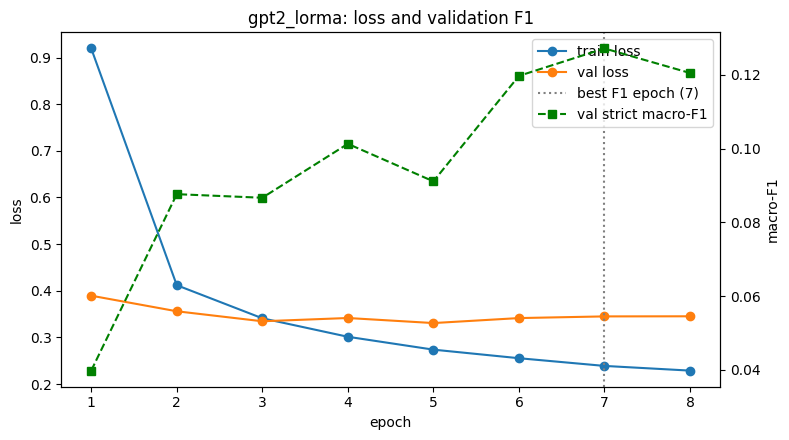

In [26]:
import matplotlib.pyplot as plt
epochs = range(1, len(history["train"]) + 1)
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(epochs, history["train"], marker="o", label="train loss")
ax1.plot(epochs, history["val"], marker="o", label="val loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss")
ax2 = ax1.twinx()
ax2.plot(epochs, history["f1"], marker="s", color="green", linestyle="--", label="val strict macro-F1")
ax2.set_ylabel("macro-F1")
best = max(range(len(history["f1"])), key=lambda i: history["f1"][i]) + 1
ax1.axvline(best, color="gray", linestyle=":", label=f"best F1 epoch ({best})")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
plt.title(f"{EXPERIMENT_NAME}: loss and validation F1")
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=150)
plt.show()

## 14. Save Final Model to Kaggle Output

In [27]:
size_kb = os.path.getsize(MODEL_PATH) / 1024
run_info = {
    "experiment": EXPERIMENT_NAME, "technique": "LoRMA", "r": LORMA_R, "alpha": LORMA_ALPHA,
    "targets": LORMA_TARGETS, "window": WINDOW_SIZE, "stride": WINDOW_STRIDE,
    "epochs_run": len(history["f1"]), "best_val_f1": max(history["f1"]),
    "trainable_params": trainable, "total_params": total_params,
}
with open(os.path.join(OUTPUT_DIR, "run_info.json"), "w") as f:
    json.dump(run_info, f, indent=2)
print(run_info)

{'experiment': 'gpt2_lorma', 'technique': 'LoRMA', 'r': 32, 'alpha': 32, 'targets': ['c_attn', 'c_proj', 'c_fc'], 'window': 1024, 'stride': 512, 'epochs_run': 8, 'best_val_f1': 0.12714255595159576, 'trainable_params': 5918233, 'total_params': 116336665}


## For reload purpose

In [28]:
# # rebuild exactly as in training, then load the saved adapter + head
# lm = PrefixLM(vocab_size=tokenizer.vocab_size, n_positions=MODEL_CONTEXT_LENGTH,
#                            n_embd=N_EMBD, n_layer=N_LAYER, n_head=N_HEAD, n_kv_head=N_KV_HEAD)
# lm.load_state_dict(load_file(os.path.join(PHASE1_CKPT_DIR, "model.safetensors")))
# ner_model = NERModel(lm, n_tags=len(TAGS))
# for p in ner_model.lm.parameters(): p.requires_grad = False
# ner_model.lm = inject_adapter_in_model(lora_cfg, ner_model.lm)   # same LoraConfig as training
# ner_model.to(device)
# print(ner_model.load_state_dict(torch.load(ADAPTER_PATH, map_location=device), strict=False).unexpected_keys)

## Predict fold3

In [29]:
test_pred = {}
for d in test_text:
    test_pred[d] = [[int(s), int(e), lab] for s, e, lab in predict_spans(ner_model, d)]

assert set(test_pred) == set(test_text), "missing or extra document ids"
for d, spans in test_pred.items():
    n = len(test_text[d])
    for s, e, lab in spans:
        assert 0 <= s < e <= n and lab in LABELS, (d, s, e, lab)
print("docs:", len(test_pred), "| total spans:", sum(len(v) for v in test_pred.values()), "| format checks OK")

docs: 35 | total spans: 6631 | format checks OK


## 21. Save prediction.json and Create CodaBench Submission ZIP

In [30]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(test_pred, f, ensure_ascii=False)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(PREDICTION_PATH, arcname="prediction.json")
print("saved:", SUBMISSION_ZIP)
with zipfile.ZipFile(SUBMISSION_ZIP) as z:
    print(z.namelist())

saved: /kaggle/working/cs781_phase2/gpt2_lorma/submission.zip
['prediction.json']


In [31]:
# import shutil
# shutil.make_archive("/kaggle/working/phase2_backup", "zip", "/kaggle/working/cs781_phase2")
# shutil.copy("/kaggle/working/a1_tokenizer.py", "/kaggle/working/cs781_phase2/a1_tokenizer.py")
# print(os.path.getsize("/kaggle/working/phase2_backup.zip") / 1e6, "MB")